# SPACECONS — 5 spatial trajectory methods on the stLearn TBI data (Pham et al., Nat Commun 2023, Fig. 2)

**Data:** 10x Visium section of a mouse brain **3 days after traumatic brain injury (TBI)** (2,442 spots in the paper).
**Biology to recover (paper, Fig. 2):** microglia activation runs from the **hypothalamus** (root) through the **thalamus** and **hippocampus** to the **injury penumbra** (end).

**Before you run (right-hand panel):** Settings → **Internet: On** · Accelerator → **GPU T4** (no upload needed — the data is downloaded from GEO, GSE236171). Then **Run All** (first run ≈ 30–45 min, mostly installing).

| # | Method | Paper | How space is used | Runs in |
|---|---|---|---|---|
| 1 | SpaceFlow | Ren et al., Nat Commun 2022 | spatial graph neural net + spatial regularisation, then DPT | main Python |
| 2 | SpaTrack | Shen et al. | optimal transport cost = expression + physical distance | main Python |
| 3 | StaVia | Stassen et al., Genome Biol 2024 | spatial smoothing + spatial kNN, random walks with memory | main Python |
| 4 | stLearn PSTS | Pham et al., Nat Commun 2023 | stSME (space + H&E image + expression), PSTS | own Python 3.11 env |
| 5 | CASCAT | Yu et al., NAR 2025 | spatial kNN graph pruned by conditional mutual information, causal tree | own Python 3.10 env |

All methods use the **same spots (after the paper's QC) and the same root spot**; every output is rank-scaled to 0–1 so they can be compared fairly.
If stLearn or CASCAT fails, the notebook prints the reason, skips it, and still runs the comparison.

**Negative-control run:** naive (uninjured) mouse brain, GEO GSM7519181. Same pipeline as the TBI 3 dpi run; results go to `/kaggle/working/run_GSM7519181`.

In [1]:
# Main environment (Kaggle's own Python): SpaceFlow, SpaTrack, StaVia. 'dependency conflict' messages are expected and harmless.
!pip install -q --no-deps SpaceFlow spaTrack
!pip install -q torch-geometric gudhi cmcrameri scanpy igraph leidenalg pot pygam
!pip install -q --no-deps pyVIA pecanpy nptyping numba-progress s_gd2 graphtools tasklogger pygsp phate scprep
!pip install -q hnswlib datashader dask scikit-image "gensim>=4.4" deprecated future termcolor gdown wget umap-learn seaborn uv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.5/42.5 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 22.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 86.8 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 277.7/277.7 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 40.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 75.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 15.7 MB/s e

## Separate environments for stLearn and CASCAT
stLearn only installs on Python < 3.13 with NumPy < 2, and CASCAT's authors pin Python 3.10 + PyTorch 2.1.1 + PyG 2.6.1.
Kaggle's own Python is newer, so each gets its **own small environment** (made with `uv`). They run as separate programs,
read the same data, and hand back one pseudotime value per spot. This takes ~10 minutes the first time.

In [2]:
# Two separate environments, made with `uv` (it downloads the right Python version itself):
#   stLearn needs Python < 3.13 and NumPy < 2        -> Python 3.11
#   CASCAT is pinned by its authors to Python 3.10, PyTorch 2.1.1 (CUDA 11.8) and PyG 2.6.1 -> exactly as in its README
import os, subprocess
ENVS = '/tmp/envs'; os.makedirs(ENVS, exist_ok=True)
STL_PY = f'{ENVS}/stl/bin/python'; CAS_PY = f'{ENVS}/cascat/bin/python'; CASCAT_DIR = f'{ENVS}/CASCAT'

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print(('OK   ' if r.returncode == 0 else 'FAIL ') + cmd[:110])
    if r.returncode: print(r.stderr[-1500:])
    return r.returncode == 0

sh('pip install -q uv')
if not os.path.exists(STL_PY):
    sh(f'uv venv -q -p 3.11 {ENVS}/stl')
    sh(f'uv pip install -q -p {STL_PY} stlearn==1.2.2 "setuptools<81"')
if not os.path.exists(CAS_PY):
    sh(f'git clone -q --depth 1 https://github.com/deepomicslab/CASCAT {CASCAT_DIR}')
    sh(f'uv venv -q -p 3.10 {ENVS}/cascat')
    sh(f'uv pip install -q -p {CAS_PY} torch==2.1.1 --index-url https://download.pytorch.org/whl/cu118')
    sh(f'uv pip install -q -p {CAS_PY} torch_geometric==2.6.1 pyg_lib torch_scatter torch_sparse torch_cluster torch_spline_conv '
       f'-f https://data.pyg.org/whl/torch-2.1.0+cu118.html')
    sh(f'uv pip install -q -p {CAS_PY} scanpy==1.10.1 matplotlib networkx scikit-misc pydot pot numpy==1.26.4 scikit-learn==1.5.2 '
       f'numba==0.60.0 numba-scipy==0.4.0 pandas==2.2.3 scipy==1.11.0 pyyaml==6.0.3 umap-learn seaborn cupy-cuda11x')   # cupy: GPU speed-up recommended in the README
sh(f'MPLBACKEND=Agg {STL_PY} -c "import stlearn, numpy; print(stlearn.__version__, numpy.__version__)"')
sh(f'MPLBACKEND=Agg {CAS_PY} -c "import torch, torch_sparse, torch_geometric; print(torch.__version__, torch.cuda.is_available())"')


OK   pip install -q uv
OK   uv venv -q -p 3.11 /tmp/envs/stl
OK   uv pip install -q -p /tmp/envs/stl/bin/python stlearn==1.2.2 "setuptools<81"
OK   git clone -q --depth 1 https://github.com/deepomicslab/CASCAT /tmp/envs/CASCAT
OK   uv venv -q -p 3.10 /tmp/envs/cascat
OK   uv pip install -q -p /tmp/envs/cascat/bin/python torch==2.1.1 --index-url https://download.pytorch.org/whl/cu1
OK   uv pip install -q -p /tmp/envs/cascat/bin/python torch_geometric==2.6.1 pyg_lib torch_scatter torch_sparse tor
OK   uv pip install -q -p /tmp/envs/cascat/bin/python scanpy==1.10.1 matplotlib networkx scikit-misc pydot pot nump
OK   MPLBACKEND=Agg /tmp/envs/stl/bin/python -c "import stlearn, numpy; print(stlearn.__version__, numpy.__version_
OK   MPLBACKEND=Agg /tmp/envs/cascat/bin/python -c "import torch, torch_sparse, torch_geometric; print(torch.__vers


True

## Download the data (GEO GSE236171) — runs automatically
The stLearn paper deposited its TBI data in GEO as **GSE236171**: naive control (GSM7519181), **TBI 3 dpi Visium (GSM7519182, used in Fig. 2)**,
and two legacy-ST samples. This cell downloads the GEO archive (~140 MB), unpacks it, and arranges sample **GSM7519182** as a standard
10x Visium folder (`filtered_feature_bc_matrix.h5` + `spatial/`). It prints every file it found — if something is reported MISSING, send that list.

In [3]:
# Download the stLearn Figure 2 data from GEO (GSE236171) and arrange the 3 dpi Visium sample as a 10x Visium folder.
# GEO samples: GSM7519181 naive control | GSM7519182 TBI 3 dpi (Visium, Fig. 2) | GSM7574423/4 legacy ST (6 h / 3 dpi)
import os, glob, gzip, shutil, tarfile, subprocess
SAMPLE = 'GSM7519181'                      # NAIVE brain, no injury (negative control)
DATA_DIR = '/kaggle/working/geo' if os.path.exists('/kaggle/working') else 'geo'
VISIUM_OUT = os.path.join(DATA_DIR, SAMPLE)
os.makedirs(DATA_DIR, exist_ok=True)

tar_path = os.path.join(DATA_DIR, 'GSE236171_RAW.tar')
if not glob.glob(f'{DATA_DIR}/**/{SAMPLE}*', recursive=True):
    if not os.path.exists(tar_path):
        subprocess.run(['wget', '-q', '-O', tar_path, 'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE236171&format=file'], check=True)
    with tarfile.open(tar_path) as t: t.extractall(DATA_DIR)

# GEO packs files per sample, often gzipped or as inner .tar(.gz): unpack everything once
changed = True
while changed:
    changed = False
    for f in glob.glob(f'{DATA_DIR}/**/*', recursive=True):
        if not os.path.isfile(f) or f == tar_path: continue
        if f.endswith(('.tar.gz', '.tgz', '.tar')):
            d = f.rsplit('.tar', 1)[0].rsplit('.tgz', 1)[0] + '_x'
            if not os.path.exists(d):
                os.makedirs(d); tarfile.open(f).extractall(d); changed = True
        elif f.endswith('.gz') and not f.endswith(('matrix.mtx.gz', 'barcodes.tsv.gz', 'features.tsv.gz', 'genes.tsv.gz')):
            out = f[:-3]
            if not os.path.exists(out):
                with gzip.open(f, 'rb') as a, open(out, 'wb') as b: shutil.copyfileobj(a, b)
                changed = True

files = sorted(f for f in glob.glob(f'{DATA_DIR}/**/*', recursive=True) if os.path.isfile(f) and f != tar_path)
print('Files from GEO:'); [print('  ', os.path.relpath(f, DATA_DIR), f'({os.path.getsize(f)/1e6:.1f} MB)') for f in files]

mine = [f for f in files if SAMPLE in f]
def pick(*keys, exclude=()):
    hits = [f for f in mine if all(k in os.path.basename(f).lower() for k in keys)
            and not any(e in os.path.basename(f).lower() for e in exclude) and not f.endswith('.gz')]
    return hits[0] if hits else None

os.makedirs(f'{VISIUM_OUT}/spatial', exist_ok=True)
h5 = pick('filtered', '.h5') or pick('.h5', exclude=('raw',))
if h5:
    shutil.copy(h5, f'{VISIUM_OUT}/filtered_feature_bc_matrix.h5')
else:                                             # matrix given as matrix.mtx / barcodes / features: rebuild the 10x .h5
    import scanpy as sc, h5py, numpy as np
    mtx = [f for f in mine if os.path.basename(f).lower().endswith(('matrix.mtx', 'matrix.mtx.gz'))][0]
    m = sc.read_10x_mtx(os.path.dirname(mtx), prefix=os.path.basename(mtx).split('matrix.mtx')[0], var_names='gene_symbols', make_unique=False)
    X = m.X.T.tocsc().astype(np.int32)
    with h5py.File(f'{VISIUM_OUT}/filtered_feature_bc_matrix.h5', 'w') as f:
        g = f.create_group('matrix'); g['barcodes'] = np.array(m.obs_names, dtype='S')
        g['data'], g['indices'], g['indptr'] = X.data, X.indices, X.indptr; g['shape'] = np.array(X.shape, dtype=np.int32)
        ft = g.create_group('features'); ft['name'] = np.array(m.var_names, dtype='S')
        ft['id'] = np.array(m.var['gene_ids'] if 'gene_ids' in m.var else m.var_names, dtype='S')
        ft['feature_type'] = np.array(['Gene Expression'] * m.n_vars, dtype='S'); ft['genome'] = np.array(['mm10'] * m.n_vars, dtype='S')
        ft['_all_tag_keys'] = np.array([b'genome'])
        f.attrs['filetype'] = 'matrix'; f.attrs['version'] = 2; f.attrs['library_ids'] = np.array([SAMPLE.encode()])
        f.attrs['chemistry_description'] = "Spatial 3' v1"; f.attrs['software_version'] = 'spaceranger-1.0.0'

for keys, name in [(('tissue_positions',), 'tissue_positions_list.csv'), (('scalefactors',), 'scalefactors_json.json'),
                   (('hires',), 'tissue_hires_image.png'), (('lowres',), 'tissue_lowres_image.png')]:
    src = pick(*keys)
    if src and name == 'tissue_positions_list.csv':          # newer Space Ranger files have a header row; the classic format has none
        lines = open(src).read().splitlines()
        if lines and lines[0].lower().startswith('barcode'): lines = lines[1:]
        open(f'{VISIUM_OUT}/spatial/{name}', 'w').write('\n'.join(lines) + '\n')
    elif src: shutil.copy(src, f'{VISIUM_OUT}/spatial/{name}')
    else: print('MISSING for', SAMPLE, ':', keys)
print('\nVisium folder ready:', VISIUM_OUT); print(sorted(os.listdir(f'{VISIUM_OUT}/spatial')))


/tmp/ipykernel_49/3522561948.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tar_path) as t: t.extractall(DATA_DIR)
/tmp/ipykernel_49/3522561948.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  os.makedirs(d); tarfile.open(f).extractall(d); changed = True


Files from GEO:
   GSM7519181_VLP4_A1_Visium.tar.gz (70.2 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/filtered_feature_bc_matrix.h5 (16.3 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/filtered_feature_bc_matrix/barcodes.tsv.gz (0.0 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/filtered_feature_bc_matrix/features.tsv.gz (0.3 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/filtered_feature_bc_matrix/matrix.mtx.gz (43.9 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/aligned_fiducials.jpg (1.8 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/detected_tissue_image.jpg (2.2 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/scalefactors_json.json (0.0 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/tissue_hires_image.png (5.4 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/tissue_lowres_image.png (0.5 MB)
   GSM7519181_VLP4_A1_Visium_x/VLP4_A_Visium/spatial/tissue_positions_list.csv (0.2 MB)
   GSM7519182_VLP4_C1_Visium.tar.gz (60.1 MB)
 

## 0. Load the Visium data, QC as in the paper, preprocess
QC as in the stLearn paper: drop spots with < 200 detected genes. Then the same preprocessing as the rest of the project:
normalise → log → 2,000 highly variable genes → PCA (30) → neighbour graph → Leiden clusters (used as brain *regions*).

Visium folder: /kaggle/working/geo/GSM7519181


/tmp/ipykernel_49/1644735634.py:18: FutureWarning: The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.
  adata = sc.read_visium(VISIUM_DIR); adata.var_names_make_unique()
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


raw: (2968, 31053)
after QC: (2965, 17824) | expression clusters (regions): 18


/tmp/ipykernel_49/1644735634.py:41: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad, color=None, ax=axes[0], show=False, title='H&E image')
/tmp/ipykernel_49/1644735634.py:42: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ad, color='region', ax=axes[1], show=False, title='Expression clusters (Leiden)', spot_size=None)


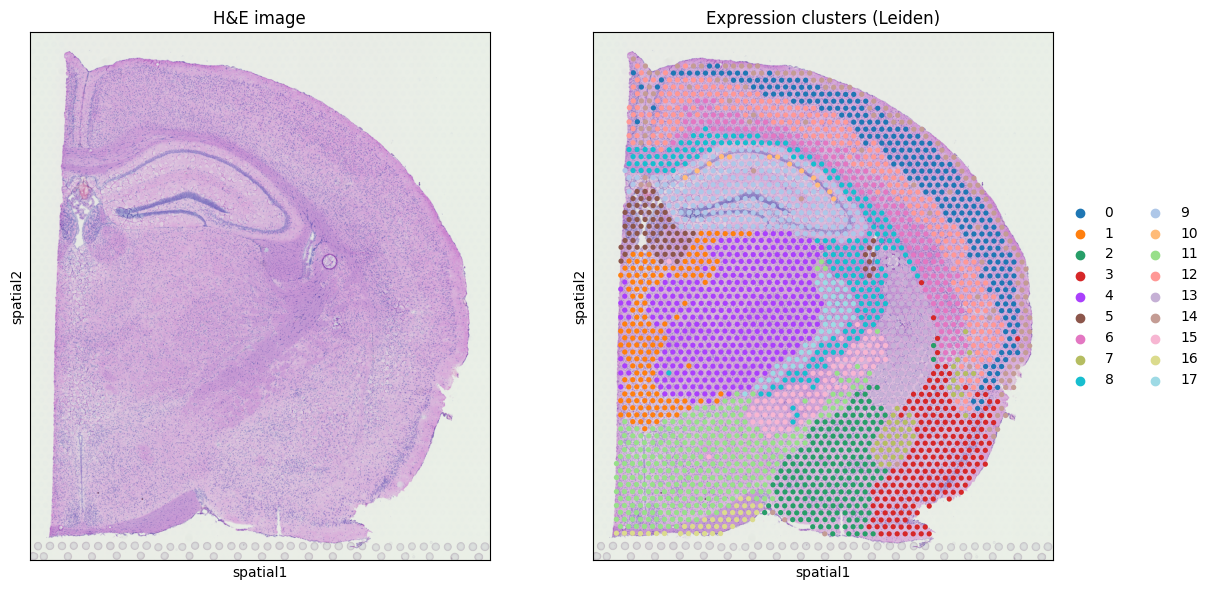

In [4]:
import glob, os, json
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr

OUT = f'/kaggle/working/run_{SAMPLE}' if os.path.exists('/kaggle/working') else f'outputs_{SAMPLE}'
os.makedirs(OUT, exist_ok=True)

# ---- find the 10x Visium folder (the one that contains filtered_feature_bc_matrix.h5 and spatial/) ----
cands = [os.path.dirname(p) for p in glob.glob('/kaggle/input/**/filtered_feature_bc_matrix.h5', recursive=True)
         + glob.glob('**/filtered_feature_bc_matrix.h5', recursive=True)]
cands = [c for c in cands if os.path.exists(os.path.join(c, 'spatial', 'tissue_positions_list.csv'))
         or os.path.exists(os.path.join(c, 'spatial', 'tissue_positions.csv'))]
if not cands and not os.path.exists(f'{VISIUM_OUT}/filtered_feature_bc_matrix.h5'):
    raise FileNotFoundError('Add the TBI Visium folder as a Kaggle input (it must contain filtered_feature_bc_matrix.h5 and spatial/)')
VISIUM_DIR = VISIUM_OUT if os.path.exists(f'{VISIUM_OUT}/filtered_feature_bc_matrix.h5') else cands[0]
print('Visium folder:', VISIUM_DIR)

adata = sc.read_visium(VISIUM_DIR); adata.var_names_make_unique()
print('raw:', adata.shape)

def rank01(t):
    t = np.asarray(t, dtype=float)
    t = np.where(np.isfinite(t), t, np.nanmax(t[np.isfinite(t)]))
    return (rankdata(t) - 1) / (len(t) - 1)

# ---- QC exactly as in the stLearn paper: drop spots with < 200 detected genes; drop genes seen in < 3 spots ----
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
raw = adata.copy()                                   # raw counts (SpaceFlow / stLearn / CASCAT normalise themselves)
ad = adata.copy()
sc.pp.normalize_total(ad, target_sum=1e4); sc.pp.log1p(ad)
sc.pp.highly_variable_genes(ad, n_top_genes=2000)
sc.tl.pca(ad, n_comps=30, mask_var='highly_variable', random_state=0)
sc.pp.neighbors(ad, n_neighbors=15, n_pcs=30, random_state=0)
sc.tl.leiden(ad, resolution=0.8, key_added='region', flavor='igraph', n_iterations=2, directed=False, random_state=0)
xy = np.asarray(ad.obsm['spatial'], dtype=float)[:, :2]
open(f'{OUT}/kept_spots.txt', 'w').write('\n'.join(ad.obs_names))
print('after QC:', ad.shape, '| expression clusters (regions):', ad.obs['region'].nunique())

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
sc.pl.spatial(ad, color=None, ax=axes[0], show=False, title='H&E image')
sc.pl.spatial(ad, color='region', ax=axes[1], show=False, title='Expression clusters (Leiden)', spot_size=None)
plt.tight_layout(); plt.show()


## Root spot (same for all 5 methods)
As in the paper, the trajectory **starts in the hypothalamus** (furthest from the injury) and **ends at the injury site**.
Each cluster is scored with marker genes (hypothalamus, thalamus, hippocampus, injury/activated microglia).
The cluster with the highest hypothalamus score is the root cluster; inside it, the root spot is picked with **stLearn's own `set_root` rule**
(CytoTRACE-like score). **Check the map** — if the wrong cluster is chosen, set `ROOT_CLUSTER` by hand and re-run this cell.
The **injury score** is used later as a biological check: a good trajectory should increase towards the injury.

hypothalamus  markers found: ['Avp', 'Oxt', 'Pmch', 'Hcrt', 'Agrp', 'Pomc', 'Gal', 'Trh', 'Ghrh', 'Cartpt']
thalamus      markers found: ['Tcf7l2', 'Prkcd', 'Slc17a6', 'Plekhg1', 'Rora', 'Zic1']
hippocampus   markers found: ['Prox1', 'C1ql2', 'Wfs1', 'Neurod6', 'Spink8', 'Fibcd1']
injury        markers found: ['Spp1', 'Lyz2', 'Cd68', 'Lgals3', 'Cd14', 'Gfap', 'Vim', 'Lcn2', 'C4b', 'Aif1', 'Hmox1']

Mean marker score per cluster (higher = more like that region):


,score_hypothalamus,score_thalamus,score_hippocampus,score_injury
region,,,,
0,-0.064,-0.352,-0.015,-0.067
1,-0.024,0.838,-0.086,-0.067
2,0.068,-0.301,0.001,-0.024
3,-0.047,-0.336,-0.004,-0.047
4,-0.063,1.095,-0.087,-0.055
5,-0.059,0.162,-0.075,0.046
6,-0.058,-0.368,0.000,-0.054
7,-0.052,-0.396,0.097,-0.057
8,-0.074,-0.197,0.012,0.156


root cluster (hypothalamus): 16 | injury cluster: 16
root spot: TTGTTTGTATTACACG-1


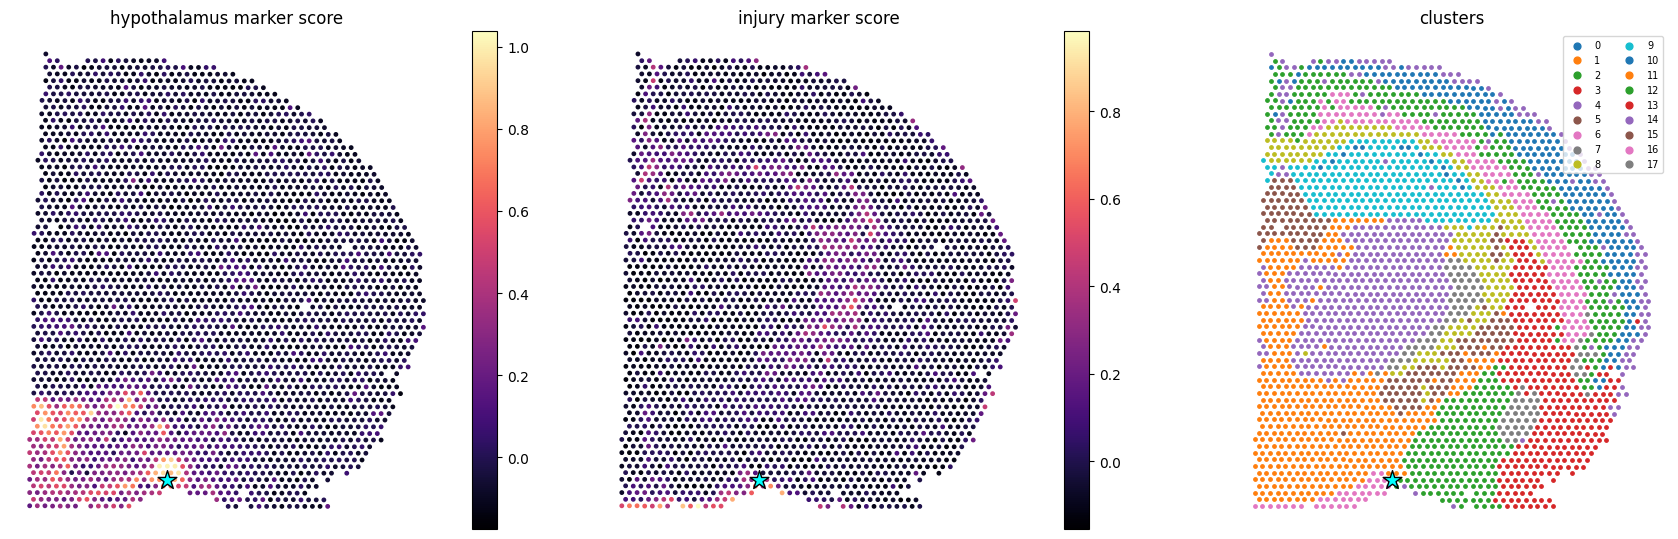

In [5]:
# ---- Which cluster is which brain region? Score each cluster with well-known marker genes ----
MARKERS = {
    'hypothalamus': ['Avp', 'Oxt', 'Pmch', 'Hcrt', 'Agrp', 'Pomc', 'Gal', 'Trh', 'Ghrh', 'Cartpt'],
    'thalamus':     ['Tcf7l2', 'Prkcd', 'Slc17a6', 'Plekhg1', 'Rora', 'Zic1'],
    'hippocampus':  ['Prox1', 'C1ql2', 'Wfs1', 'Neurod6', 'Spink8', 'Fibcd1'],
    'injury':       ['Spp1', 'Lyz2', 'Cd68', 'Lgals3', 'Cd14', 'Gfap', 'Vim', 'Lcn2', 'C4b', 'Aif1', 'Hmox1'],
}
for name, genes in MARKERS.items():
    g = [x for x in genes if x in ad.var_names]
    if g: sc.tl.score_genes(ad, g, score_name=f'score_{name}', random_state=0)
    else: ad.obs[f'score_{name}'] = 0.0
    print(f'{name:13s} markers found: {g}')
cl_scores = ad.obs.groupby('region', observed=True)[[f'score_{k}' for k in MARKERS]].mean()
print('\nMean marker score per cluster (higher = more like that region):'); display(cl_scores.round(3))

# ---- Root, as in the stLearn paper: start in the HYPOTHALAMUS (furthest from the injury), end at the injury site.
#      Set ROOT_CLUSTER by hand if the automatic choice looks wrong on the map above.
ROOT_CLUSTER = None
if ROOT_CLUSTER is None:
    ROOT_CLUSTER = cl_scores['score_hypothalamus'].idxmax()
print('root cluster (hypothalamus):', ROOT_CLUSTER, '| injury cluster:', cl_scores['score_injury'].idxmax())

# ---- root spot inside that cluster: stLearn's set_root rule (CytoTRACE-like: genes that rise with
#      the number of expressed genes; the most 'immature-looking' spot wins) ----
sub = ad[ad.obs['region'] == ROOT_CLUSTER]
Xs = sub.X.toarray() if hasattr(sub.X, 'toarray') else np.asarray(sub.X)
n_expr = (Xs > 0).sum(1).astype(float)
Xc = Xs - Xs.mean(0); nc = n_expr - n_expr.mean()
corr = (Xc * nc[:, None]).sum(0) / (np.sqrt((Xc ** 2).sum(0) * (nc ** 2).sum()) + 1e-12)
top = np.argsort(-np.nan_to_num(corr))[:1000]
cyto = Xs[:, top].mean(1)
root = int(np.where(ad.obs_names == sub.obs_names[int(np.argmax(cyto))])[0][0])
ROOT_BARCODE = ad.obs_names[root]
ad.uns['iroot'] = root
print('root spot:', ROOT_BARCODE)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for a, k in zip(axes, ['hypothalamus', 'injury']):
    s = a.scatter(xy[:, 0], -xy[:, 1], c=ad.obs[f'score_{k}'], s=6, cmap='magma'); plt.colorbar(s, ax=a)
    a.set_title(f'{k} marker score')
for lab in ad.obs['region'].cat.categories:
    m = (ad.obs['region'] == lab).values; axes[2].scatter(xy[m, 0], -xy[m, 1], s=6, label=lab)
axes[2].legend(fontsize=7, markerscale=2, ncol=2); axes[2].set_title('clusters')
for a in axes:
    a.scatter(xy[root, 0], -xy[root, 1], c='cyan', s=200, marker='*', edgecolors='k'); a.set_aspect('equal'); a.axis('off')
plt.tight_layout(); plt.show()

def save_pt(col, name):
    pd.DataFrame({'barcode': ad.obs_names, 'x': xy[:, 0], 'y': xy[:, 1], 'region': ad.obs['region'].values,
                  'pseudotime': ad.obs[col].values, 'method': name}).to_csv(f'{OUT}/pt_{name}.csv', index=False)
    print(name, '| root cluster mean:', round(ad.obs.loc[ad.obs['region'] == ROOT_CLUSTER, col].mean(), 3),
          '| corr. with injury score:', round(spearmanr(ad.obs[col], ad.obs['score_injury'])[0], 3))


## 1. SpaceFlow (graph neural network + spatial regularisation, then DPT from the root)

In [6]:
from SpaceFlow import SpaceFlow
import networkx as nx, scipy.sparse as sp
# compatibility fix: SpaceFlow 1.0.4 calls a networkx function that newer networkx removed
if not hasattr(nx, 'to_scipy_sparse_matrix'):
    nx.to_scipy_sparse_matrix = lambda G, format='csr', **kw: sp.csr_matrix(nx.to_scipy_sparse_array(G, format=format, **kw))

EPOCHS = 1000          # SpaceFlow default; early stopping usually ends sooner
sf = SpaceFlow.SpaceFlow(adata=raw.copy())
sf.preprocessing_data(n_top_genes=2000)          # normalise, log, HVGs, PCA, spatial graph (alpha complex)
emb = sf.train(embedding_save_filepath=f'{OUT}/spaceflow_embedding.tsv',
               spatial_regularization_strength=0.1, z_dim=50, lr=1e-3,
               epochs=EPOCHS, max_patience=50, min_stop=100, random_seed=42, gpu=0)
print('embedding shape:', emb.shape)

e = sc.AnnData(emb); e.obs_names = ad.obs_names
sc.pp.neighbors(e, n_neighbors=20, use_rep='X')
sc.tl.diffmap(e, n_comps=15)
e.uns['iroot'] = int(root)
sc.tl.dpt(e)
ad.obs['t_spaceflow'] = rank01(e.obs['dpt_pseudotime'].values)
save_pt('t_spaceflow', 'spaceflow')

Epoch 2/1000, Loss: 1.5879833698272705
Epoch 12/1000, Loss: 1.2116303443908691
Epoch 22/1000, Loss: 0.6472887396812439
Epoch 32/1000, Loss: 0.26670777797698975
Epoch 42/1000, Loss: 0.14890272915363312
Epoch 52/1000, Loss: 0.1027907282114029
Epoch 62/1000, Loss: 0.08152934908866882
Epoch 72/1000, Loss: 0.0723787397146225
Epoch 82/1000, Loss: 0.061173804104328156
Epoch 92/1000, Loss: 0.0553094744682312
Epoch 102/1000, Loss: 0.0558243989944458
Epoch 112/1000, Loss: 0.049521178007125854
Epoch 122/1000, Loss: 0.050141554325819016
Epoch 132/1000, Loss: 0.05183315649628639
Epoch 142/1000, Loss: 0.04784548655152321
Epoch 152/1000, Loss: 0.051096703857183456
Epoch 162/1000, Loss: 0.04544186219573021
Epoch 172/1000, Loss: 0.04776201769709587
Epoch 182/1000, Loss: 0.04262194037437439
Epoch 192/1000, Loss: 0.04436632990837097
Epoch 202/1000, Loss: 0.04410272091627121
Epoch 212/1000, Loss: 0.04053172841668129
Epoch 222/1000, Loss: 0.0442960262298584
Epoch 232/1000, Loss: 0.041052017360925674
Epoch 

## 2. SpaTrack (optimal transport: cost = expression distance + physical distance)

In [7]:
import numpy as np
if not hasattr(np, 'Inf'):
    np.Inf = np.inf          # compatibility fix: spaTrack 0.1.1 uses a name removed in NumPy 2
import spaTrack as spt

ALPHA_SPACE, ALPHA_EXPR = 1, 1
st = ad.copy()
st.obsm['X_spatial'] = xy
st.obs['cluster'] = ad.obs['region'].astype(str)
st.obsp['trans'] = spt.get_ot_matrix(st, data_type='spatial', alpha1=ALPHA_SPACE, alpha2=ALPHA_EXPR)
start_cells = spt.set_start_cells(st, select_way='coordinates', start_point=tuple(xy[root]),
                                  basis='spatial', n_neigh=20)
print('start cells:', len(start_cells), '| their tissues:', st.obs['region'].iloc[list(start_cells)].value_counts().to_dict())
ad.obs['t_spatrack'] = rank01(spt.get_ptime(st, list(start_cells)))
save_pt('t_spatrack', 'spatrack')

/usr/local/lib/python3.13/dist-packages/ot/datasets.py:204: SyntaxWarning: invalid escape sequence '\d'
  positive floating numbers corresponding to the isotropic variances in the principal subspace, for the source and target distributions, respectively. The same as \delta in :ref:`[1] <references-make_gauss-hd>`, Proposition 2.2


start cells: 20 | their tissues: {'16': 9, '11': 6, '2': 4, '14': 1, '1': 0, '0': 0, '6': 0, '3': 0, '4': 0, '5': 0, '9': 0, '8': 0, '7': 0, '10': 0, '13': 0, '12': 0, '15': 0, '17': 0}
spatrack | root cluster mean: 0.006 | corr. with injury score: -0.19


/usr/local/lib/python3.13/dist-packages/spaTrack/single_time/velocity.py:204: FutureWarning:

Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`



## 3. StaVia (spatial smoothing + spatial kNN, random walks with memory)

/usr/local/lib/python3.13/dist-packages/phate/__init__.py
2026-10-22 06:50:10.266785	These slices are present: [np.str_('slice1')]
x_coords shape (2965, 2)
x_genes shape (2965, 2000)
nsamples (slices) 2965


/usr/local/lib/python3.13/dist-packages/pyVIA/examples.py:26: FutureWarning:

The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead



2026-10-22 06:50:11.039527	Shape spatial neighbors and data shape (2965, 8) (2965, 8)
2026-10-22 06:50:11.160031	Spatial gene smoothing... (2965, 8)
2026-10-22 06:50:11.622563	Running VIA over input data of 2965 (samples) x 30 (features)
2026-10-22 06:50:11.622659	Knngraph has 30 neighbors
2026-10-22 06:50:12.195064	Since no slice-labels were provided, all cells are assumed to be from the same tissue slice 
2026-10-22 06:50:12.195170	Using spatial information to guide knn graph construction. Note! If cells are from different slices of tissue, provide a list of tissue-slice IDs 
2026-10-22 06:50:12.195624	These slices are present: ['slice1']
2026-10-22 06:50:12.962856	Shape neighbors (2965, 30) and spatial neighbors (2965, 15)
2026-10-22 06:50:12.963668	Shape of spatially augmented neighbors (2965, 45)
2026-10-22 06:50:13.228137	Finished global pruning of 30-knn graph used for clustering at level of 0.15. Kept 49.9 % of edges. 
2026-10-22 06:50:13.228243	using spatial coords to augment 

/usr/local/lib/python3.13/dist-packages/pyVIA/core.py:176: UserWarning:




  0%|          | 0/1300 [00:00<?, ?it/s]

memory for rw2 hittings times  2. Using rw2 based pt
2026-10-22 06:50:24.052390	Identifying terminal clusters corresponding to unique lineages...
2026-10-22 06:50:24.052419	Closeness:[0, 1, 3, 4, 6, 10, 13, 15, 16, 17, 20, 25, 26, 28, 29, 30]
2026-10-22 06:50:24.052444	Betweenness:[0, 1, 2, 3, 4, 5, 8, 10, 12, 13, 15, 16, 19, 23, 25, 28, 29, 31]
2026-10-22 06:50:24.052457	Out Degree:[0, 1, 3, 4, 5, 6, 10, 12, 13, 15, 16, 17, 19, 20, 22, 23, 26, 28, 30, 32]
2026-10-22 06:50:24.052666	Cluster 1 had 3 or more neighboring terminal states [np.int64(3), np.int64(6), np.int64(10)] and so we removed cluster 3
2026-10-22 06:50:24.052722	Cluster 6 had 3 or more neighboring terminal states [np.int64(1), np.int64(10), np.int64(26)] and so we removed cluster 26
2026-10-22 06:50:24.052756	Cluster 13 had 3 or more neighboring terminal states [np.int64(4), np.int64(19), np.int64(20)] and so we removed cluster 19
2026-10-22 06:50:24.052778	Cluster 15 had 3 or more neighboring terminal states [np.int64(

/usr/local/lib/python3.13/dist-packages/pyVIA/core.py:176: UserWarning:




  0%|          | 0/1000 [00:00<?, ?it/s]

2026-10-22 06:50:28.768312	Cluster or terminal cell fate 0 is reached 719.0 times
2026-10-22 06:50:28.825583	Cluster or terminal cell fate 1 is reached 209.0 times
2026-10-22 06:50:28.877384	Cluster or terminal cell fate 4 is reached 289.0 times
2026-10-22 06:50:28.935710	Cluster or terminal cell fate 5 is reached 215.0 times
2026-10-22 06:50:28.998566	Cluster or terminal cell fate 6 is reached 195.0 times
2026-10-22 06:50:29.054357	Cluster or terminal cell fate 10 is reached 209.0 times
2026-10-22 06:50:29.120337	Cluster or terminal cell fate 15 is reached 71.0 times
2026-10-22 06:50:29.163199	Cluster or terminal cell fate 17 is reached 720.0 times
2026-10-22 06:50:29.210656	Cluster or terminal cell fate 20 is reached 615.0 times
2026-10-22 06:50:29.273739	Cluster or terminal cell fate 23 is reached 56.0 times
2026-10-22 06:50:29.336977	Cluster or terminal cell fate 28 is reached 71.0 times
2026-10-22 06:50:29.400496	Cluster or terminal cell fate 29 is reached 66.0 times
2026-10-22 06

/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning:

Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.



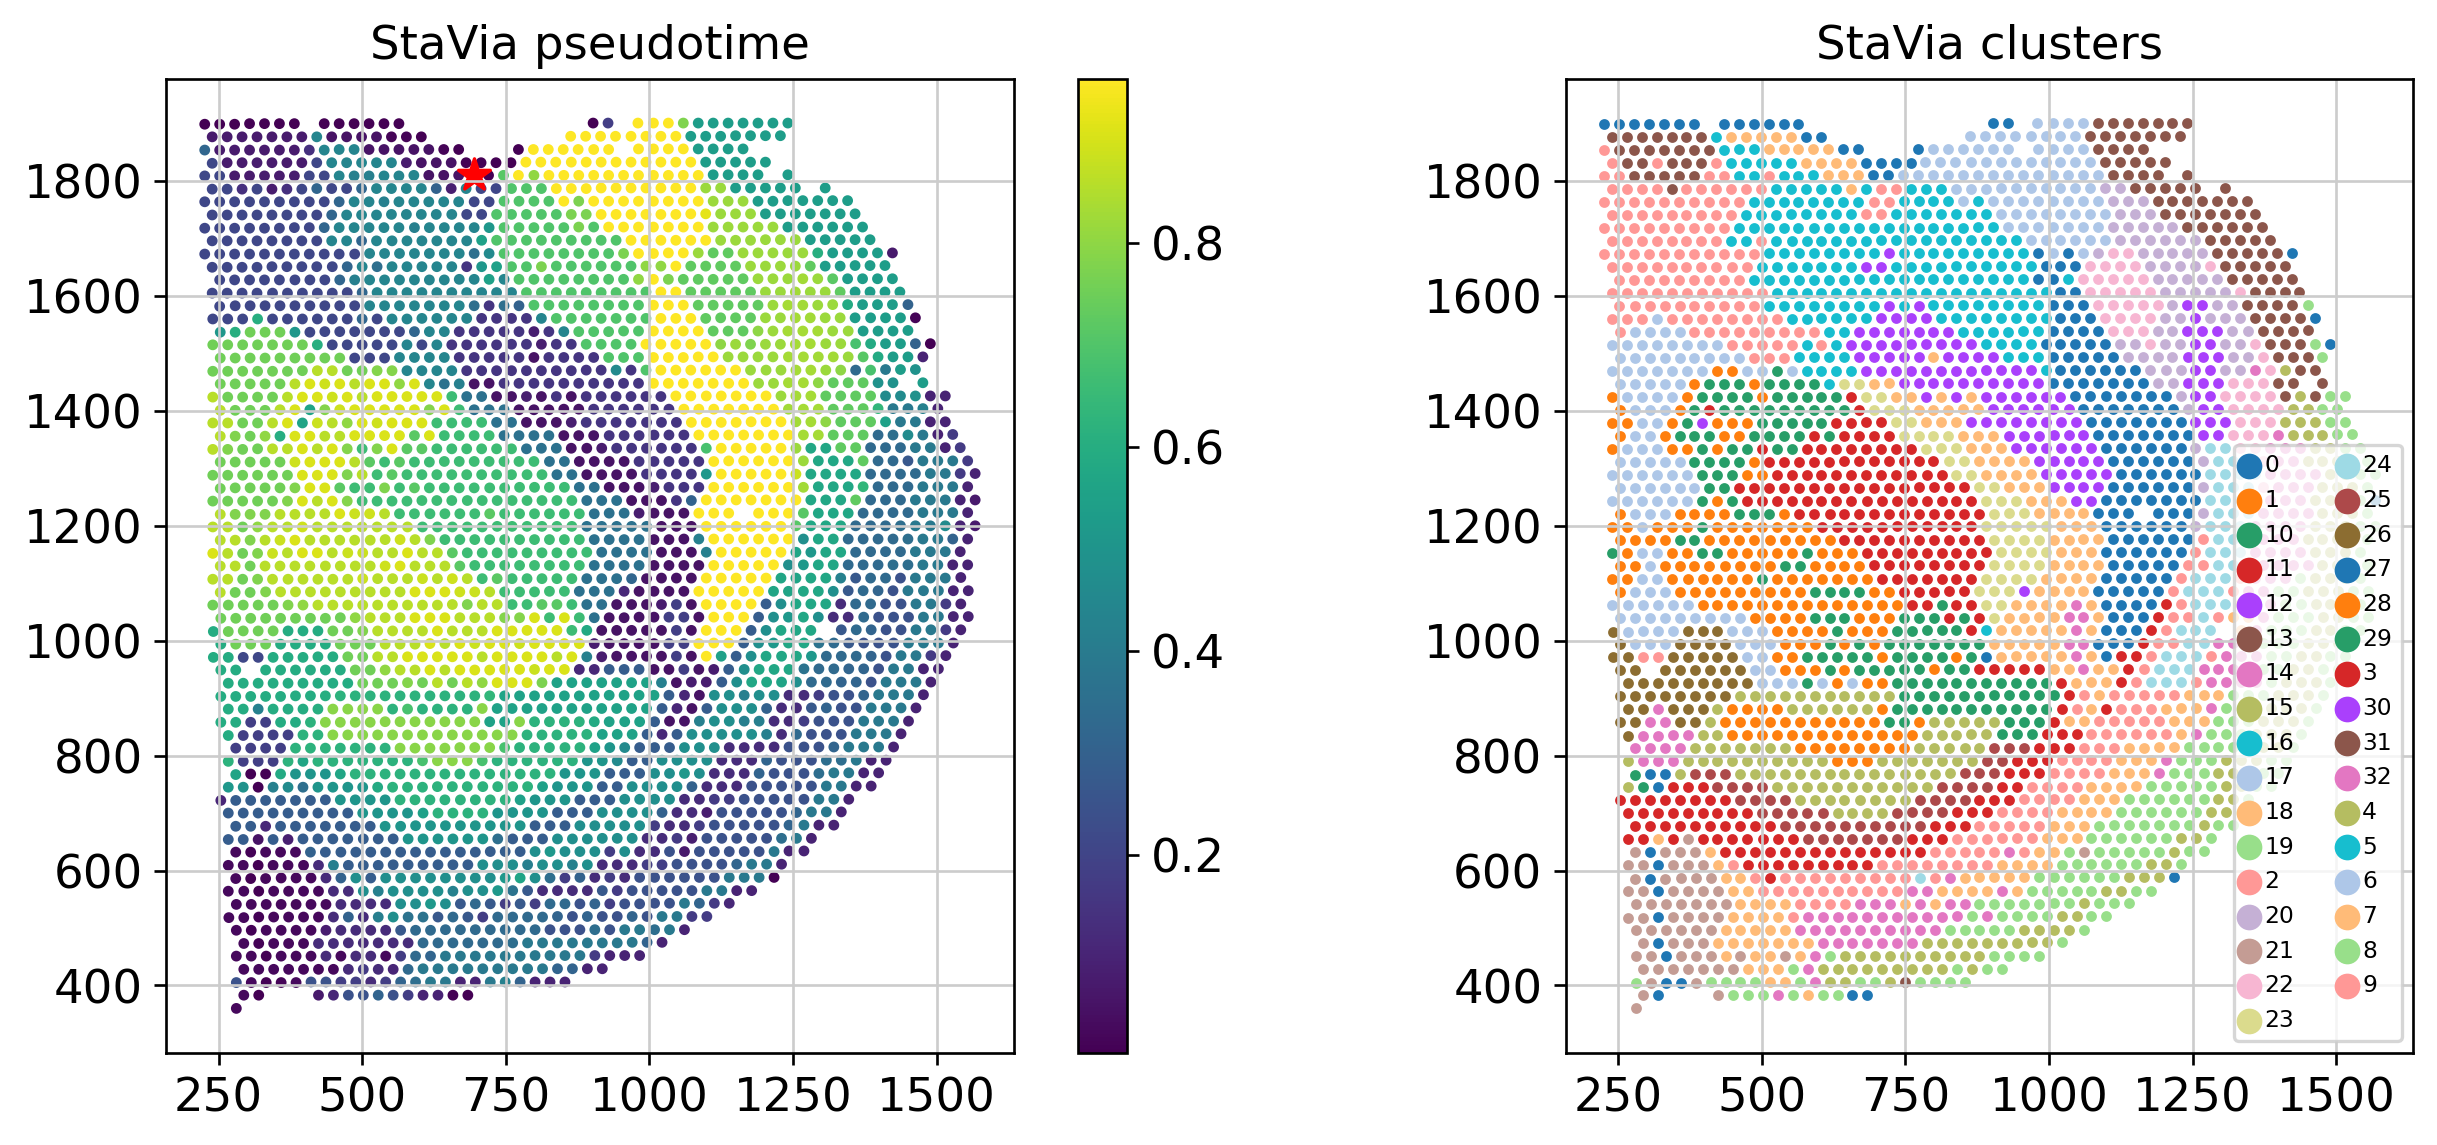

In [8]:
# ---- compatibility fixes (pyVIA was written for NumPy 1 and older SciPy) ----
import numpy as np, scipy.sparse as sp
for old, new in {'bool8':'bool_','object0':'object_','int0':'intp','uint0':'uintp','float_':'float64',
                 'complex_':'complex128','unicode_':'str_','string_':'bytes_','longfloat':'longdouble',
                 'singlecomplex':'complex64','cfloat':'complex128','longcomplex':'clongdouble',
                 'clongfloat':'clongdouble','void0':'void','bytes0':'bytes_','str0':'str_'}.items():
    if old not in np.__dict__: setattr(np, old, getattr(np, new))
for old, val in {'Inf':np.inf,'NaN':np.nan,'Infinity':np.inf,'NINF':-np.inf,'PINF':np.inf}.items():
    if old not in np.__dict__: setattr(np, old, val)
import matplotlib, matplotlib.cm as cm
if not hasattr(cm, 'get_cmap'): cm.get_cmap = matplotlib.colormaps.get_cmap   # removed in new matplotlib
import pyVIA.utils_via as uv, pyVIA.core as vc
def _sparse_from_igraph(graph, weight_attr=None):            # fixed copy of pyVIA's helper (new SciPy rejects zip())
    edges = graph.get_edgelist()
    w = list(graph.es[weight_attr]) if weight_attr else [1] * len(edges)
    if not graph.is_directed():
        edges = edges + [(b, a) for a, b in edges]; w = w + w
    n = graph.vcount()
    if not edges: return sp.csr_matrix((n, n))
    r, c = map(np.asarray, zip(*edges))
    return sp.csr_matrix((np.asarray(w, float), (r, c)), shape=(n, n))
uv.get_sparse_from_igraph = vc.get_sparse_from_igraph = _sparse_from_igraph
from pyVIA.core import VIA
from pyVIA.utils_via import spatial_input
from sklearn.decomposition import PCA

# ---- Method 5: StaVia ----
SPATIAL_WEIGHT = 0.3     # how much each spot's expression is mixed with its 8 spatial neighbours (paper uses 0.3 to 0.5)
Xh = ad[:, ad.var['highly_variable']].X                      # log-normalised HVG expression
Xh = Xh.toarray() if sp.issparse(Xh) else np.asarray(Xh)
Xs = spatial_input(Xh, xy.astype(float), knn_spatial=8, spatial_weight=SPATIAL_WEIGHT)   # step 1: spatial smoothing
Xs = Xs.toarray() if sp.issparse(Xs) else np.asarray(Xs)
pcs_sv = PCA(30, random_state=0).fit_transform((Xs - Xs.mean(0)) / (Xs.std(0) + 1e-8))

v = VIA(data=pcs_sv, true_label=list(ad.obs['region'].astype(str)), root_user=[int(root)],
        knn=30, memory=5, random_seed=42, num_threads=4,
        spatial_coords=xy.astype(float), do_spatial_knn=True, spatial_knn=15)                  # step 2: spatial kNN
v.run_VIA()

pt = np.asarray(v.single_cell_pt_markov, dtype=float)
assert len(pt) == ad.n_obs, f'StaVia returned {len(pt)} values for {ad.n_obs} spots'
ad.obs['t_stavia'] = rank01(pt)
ad.obs['stavia_cluster'] = pd.Categorical(np.asarray(v.labels).astype(str))
print('StaVia clusters:', ad.obs['stavia_cluster'].nunique(), '| terminal clusters:', v.terminal_clusters)
save_pt('t_stavia', 'stavia')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
s = axes[0].scatter(xy[:, 0], xy[:, 1], c=ad.obs['t_stavia'], s=5, cmap='viridis'); plt.colorbar(s, ax=axes[0])
axes[0].scatter(xy[root, 0], xy[root, 1], c='red', s=100, marker='*'); axes[0].set_title('StaVia pseudotime')
for k in ad.obs['stavia_cluster'].cat.categories:
    m = (ad.obs['stavia_cluster'] == k).values; axes[1].scatter(xy[m, 0], xy[m, 1], s=5, label=k)
axes[1].legend(fontsize=7, markerscale=3, ncol=2); axes[1].set_title('StaVia clusters')
for a in axes: a.set_aspect('equal')
plt.tight_layout(); plt.show()


## 4. stLearn PSTS (full version, with the H&E image)
Steps, as in the stLearn tutorial: normalise/log → PCA → **cut an image tile around each spot and describe it with a ResNet50 CNN** →
**stSME** (smooth each spot with neighbours that are close in space, look alike in the image and in expression) → PCA → Louvain clusters →
**PSTS**: diffusion pseudotime from our root on the stSME graph + spatial sub-clusters, and the cluster-level trajectory.
The next cell saves the script; the cell after runs it in the Python 3.11 environment.

In [9]:
%%writefile run_stlearn_psts.py
import os; os.environ['MPLBACKEND'] = 'Agg'   # this runs outside Jupyter: never inherit the notebook's inline plotting backend
"""stLearn PSTS (Pham et al., Nat Commun 2023) following the official stLearn tutorial.
Runs in its own Python 3.11 environment (stLearn needs Python < 3.13 and NumPy < 2).
Input : a 10x Visium folder (filtered_feature_bc_matrix.h5 + spatial/), the root spot barcode, and the spots to keep.
Output: CSV with one stLearn pseudotime value per spot (+ its stSME louvain cluster)."""

import argparse, os, json, numpy as np, pandas as pd
ap = argparse.ArgumentParser()
ap.add_argument('--visium_dir', required=True); ap.add_argument('--root_barcode', required=True)
ap.add_argument('--keep', required=True, help='text file with barcodes to keep (same spots as the other methods)')
ap.add_argument('--out', required=True); ap.add_argument('--tile_dir', default='/tmp/stl_tiles')
ap.add_argument('--resolution', type=float, default=1.0); ap.add_argument('--eps', type=float, default=50)
ap.add_argument('--no_imagenet_weights', action='store_true', help='testing only: offline, use untrained CNN')
a = ap.parse_args()

if a.no_imagenet_weights:                      # offline test only; on Kaggle the ImageNet ResNet50 weights download normally
    import keras.applications.resnet50 as kr
    _R = kr.ResNet50; kr.ResNet50 = lambda *x, **k: _R(*x, **{**k, 'weights': None})
import stlearn as st, scanpy as sc

data = st.Read10X(a.visium_dir)
data.var_names_make_unique()
keep = [l.strip() for l in open(a.keep) if l.strip()]
data = data[data.obs_names.isin(keep)].copy()
data.layers['raw_count'] = data.X.copy()

# 1) preprocessing (stLearn tutorial)
st.pp.filter_genes(data, min_cells=3)
st.pp.normalize_total(data); st.pp.log1p(data)
st.em.run_pca(data, n_comps=50, random_state=0)

# 2) morphology: cut an image tile around every spot and describe it with a ResNet50 CNN
st.pp.tiling(data, a.tile_dir)
st.pp.extract_feature(data)

# 3) stSME: smooth each spot with neighbours that are close in space AND look alike in the image AND in expression
st.spatial.SME.SME_normalize(data, use_data='raw', weights='weights_matrix_all')
d = data.copy(); d.X = d.obsm['raw_SME_normalized']
st.pp.scale(d); st.em.run_pca(d, n_comps=50, random_state=0)
st.pp.neighbors(d, n_neighbors=25, use_rep='X_pca', random_state=0)
st.tl.clustering.louvain(d, resolution=a.resolution, random_state=0)

# 4) PSTS: root = the same root spot used by all methods; diffusion pseudotime on the stSME graph + spatial sub-clusters
root_idx = int(np.where(d.obs_names == a.root_barcode)[0][0])
d.uns['iroot'] = root_idx
st.spatial.trajectory.pseudotime(d, eps=a.eps, use_rep='X_pca', use_label='louvain', max_nodes=5)   # allow 4-cluster paths like the paper's
root_cl = str(d.obs['louvain'].iloc[root_idx])
info = {'n_spots': int(d.n_obs), 'n_louvain': int(d.obs['louvain'].nunique()), 'root_cluster': root_cl}

# 5) PSTS global trajectory (cluster level), as in the paper: a path of connected clusters starting at the root's cluster.
#    stLearn lists the valid paths in uns['available_paths']; we try the longest ones that start at the root cluster.
paths = [p for p in d.uns.get('available_paths', {}).values() if str(p[0]) == root_cl and len(p) > 1]
cl_pt = d.obs.groupby('louvain', observed=True)['dpt_pseudotime'].mean()
paths.sort(key=lambda p: (len(p), cl_pt.get(str(p[-1]), 0)), reverse=True)
for p in paths:
    try:
        st.spatial.trajectory.pseudotimespace_global(d, use_label='louvain', list_clusters=[str(c) for c in p])
        info['psts_path'] = [str(c) for c in p]; info.pop('psts_global_error', None); break
    except Exception as e:
        info['psts_global_error'] = repr(e)[:200]
else:
    info.setdefault('psts_global_error', 'no available path from the root cluster')

pd.DataFrame({'barcode': d.obs_names, 'stlearn_pseudotime': d.obs['dpt_pseudotime'].values,
              'stlearn_cluster': d.obs['louvain'].astype(str).values}).to_csv(a.out, index=False)
json.dump(info, open(a.out.replace('.csv', '_info.json'), 'w'), indent=1)
print('stLearn PSTS done:', info)


Writing run_stlearn_psts.py


In [ ]:
# helper: run a separate program and SHOW its progress live (instead of only at the end), with elapsed time
import subprocess, time, os, sys
def run_live(cmd, skip=lambda l: False, every=1):
    t0 = time.time(); env = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONUNBUFFERED': '1'}
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
    tail, k = [], 0
    for line in p.stdout:
        line = line.rstrip(); tail = (tail + [line])[-40:]
        if not line or skip(line): continue
        k += 1
        if k % every == 0: print(f'[{(time.time() - t0) / 60:5.1f} min] {line[:200]}', flush=True)
    p.wait(); print(f'--- finished in {(time.time() - t0) / 60:.1f} min, exit code {p.returncode}')
    return p.returncode, '\n'.join(tail)

import json
# ---- run stLearn PSTS in its own environment, with live progress (skipped if a result for these spots already exists) ----
if not os.path.exists(f'{OUT}/raw_stlearn.csv'):
    cmd = [STL_PY, 'run_stlearn_psts.py', '--visium_dir', VISIUM_DIR, '--root_barcode', ROOT_BARCODE,
           '--keep', f'{OUT}/kept_spots.txt', '--out', f'{OUT}/raw_stlearn.csv', '--tile_dir', '/tmp/stl_tiles']
    rc, tail = run_live(cmd, skip=lambda l: ('it/s' in l or 's/it' in l) and '100%' not in l)   # hide progress-bar spam
    if rc != 0: print(tail); print('stLearn did not finish -> skipped (the comparison will run without it)')
if os.path.exists(f'{OUT}/raw_stlearn.csv'):
    res = pd.read_csv(f'{OUT}/raw_stlearn.csv', index_col='barcode')
    print('spots returned:', len(res), 'of', ad.n_obs)
    ad.obs['t_stlearn'] = rank01(res['stlearn_pseudotime'].reindex(ad.obs_names).values)
    ad.obs['stlearn_cluster'] = res['stlearn_cluster'].reindex(ad.obs_names).astype(str).values
    print(json.load(open(f'{OUT}/raw_stlearn_info.json')))
    save_pt('t_stlearn', 'stlearn')


[  0.0 min] /tmp/envs/stl/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources pa
[  0.0 min]   from pkg_resources import get_distribution, DistributionNotFound
[  0.1 min] /tmp/envs/stl/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
[  0.1 min]   utils.warn_names_duplicates("var")
[  0.1 min] /tmp/envs/stl/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
[  0.1 min]   utils.warn_names_duplicates("var")
[  0.2 min] Normalization step is finished in adata.X
[  0.2 min] Log transformation step is finished in adata.X
[  0.3 min] PCA is done! Generated in adata.obsm['X_pca'], adata.uns['pca'] and adata.varm['PCs']
[  0.3 min] Tiling image:   0%|    

## 5. CASCAT (causal trajectories; Yu et al., NAR 2025)
Run exactly as in the authors' README (`main.py --mode train`, which trains and then infers), with the authors' **Visium settings** (`HER2ST.yml`).
CASCAT needs region labels (`obs['cluster']`) — we give it our Leiden regions — and the root: our root cluster and root spot.
Its per-spot output is `cascat_pseudotime`.

**Runtime note:** CASCAT's training is quick (~1 min per trial); almost all of its time is the **causal-tree step**, which computes a conditional-mutual-information value for every pair of regions at every branch.
With the authors' kernel-density estimator this takes **hours** on Kaggle for 16 regions. By default this notebook uses CASCAT's own **binned CMI estimator** (`CASCAT_KDE = 0`, a few minutes), 2 trials × 50 epochs, and a **60-minute time limit** after which CASCAT is skipped. Set `CASCAT_KDE = 1` and `5, 100` to reproduce the authors' exact settings.

In [ ]:
%%writefile run_cascat.py
import os; os.environ['MPLBACKEND'] = 'Agg'   # this runs outside Jupyter: never inherit the notebook's inline plotting backend
"""CASCAT (Yu et al., Nucleic Acids Research 2025) on one spatial section, following the authors' README.
Runs inside the CASCAT folder, in its own Python 3.10 environment.
Input : an h5ad with raw counts in X, obsm['spatial'], obs['cluster'] (region labels) and uns['start_id'] (root spot).
Output: CSV with CASCAT's per-spot pseudotime (adata.obs['cascat_pseudotime']) and its clusters."""
import argparse, os, sys, subprocess, yaml, glob
ap = argparse.ArgumentParser()
ap.add_argument('--cascat_dir', required=True); ap.add_argument('--h5ad', required=True)
ap.add_argument('--root_cluster', required=True); ap.add_argument('--out', required=True)
ap.add_argument('--work', default='/tmp/cascat_run'); ap.add_argument('--device', default='cuda')
ap.add_argument('--ntrials', type=int, default=5); ap.add_argument('--epochs', type=int, default=100)
ap.add_argument('--kde', type=int, default=1, help='1 = authors default (kernel-density CMI in the tree step, slow); 0 = CASCAT binned CMI estimator (fast)')
a = ap.parse_args()

cfg = yaml.safe_load(open(os.path.join(a.cascat_dir, 'config/yaml/CMI/HER2ST.yml')))   # authors' Visium settings
cfg.update({'data_name': 'TBI', 'adata_file': os.path.abspath(a.h5ad), 'root': str(a.root_cluster),
            'device': a.device, 'ntrials': a.ntrials, 'epochs': a.epochs, 'species': 'Mouse',
            'img_dir': f'{a.work}/img/', 'clu_dir': f'{a.work}/clu/', 'output_dir': f'{a.work}/result/',
            'CMI_dir': f'{a.work}/cmi/'})
cfg.setdefault('ncomp', 15)                      # diffusion components for pseudotime (value from the authors' tree1.yml)
os.makedirs(a.work, exist_ok=True); os.makedirs(cfg['img_dir'], exist_ok=True)
yml = f'{a.work}/TBI.yml'; yaml.safe_dump(cfg, open(yml, 'w'))
print('CASCAT config:', {k: cfg[k] for k in ['a_k', 'percent', 'epochs', 'ntrials', 'root', 'hvg', 'norm_target', 'device']})

# CASCAT hard-codes kde=True in infer.py; make it follow --kde (authors' own alternative estimator in BinaryCMITree)
inf = os.path.join(a.cascat_dir, 'infer.py'); src = open(inf).read()
if 'CASCAT_KDE' not in src:
    src = 'import os\n' + src.replace("save_dir=self.save_path, kde=True)", "save_dir=self.save_path, kde=os.environ.get('CASCAT_KDE', '1') == '1')")
    open(inf, 'w').write(src)
os.environ['CASCAT_KDE'] = str(a.kde)
r = subprocess.run([sys.executable, 'main.py', '--YAML', yml, '--mode', 'train', '--verbose', 'True'], cwd=a.cascat_dir, env={**os.environ, 'MPLBACKEND': 'Agg'})
if r.returncode != 0: sys.exit(r.returncode)

import scanpy as sc, pandas as pd
res = sc.read_h5ad(os.path.join(cfg['output_dir'], 'data_processed.h5ad'))
pd.DataFrame({'barcode': res.obs_names, 'cascat_pseudotime': res.obs['cascat_pseudotime'].values,
              'cascat_cluster': res.obs['cascat_clusters'].astype(str).values}).to_csv(a.out, index=False)
print('CASCAT done:', res.n_obs, 'spots | root cluster:', res.uns.get('root'),
      '| tree:', res.uns['cascat_connectivities'].shape if 'cascat_connectivities' in res.uns else None)


In [ ]:
import os, sys, time, subprocess, torch
# ---- settings ----
CASCAT_TRIALS, CASCAT_EPOCHS = 2, 50   # authors' default 5 x 100 (training is quick; the slow part is the causal tree below)
CASCAT_KDE = 0                         # 0 = CASCAT's binned CMI estimator in the tree step (fast, minutes); 1 = authors' kernel-density CMI (hours)
CASCAT_MAX_MIN = 60                    # time limit in minutes: if exceeded, CASCAT is stopped and skipped so the notebook continues

def run_live(cmd, skip=lambda l: False, timeout_min=None, done_file=None):
    # prints the tool's output live; stops at the time limit, or 2 min after done_file appears with no new output (avoids the end-of-run hang)
    import threading, queue
    t0 = time.time(); env = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONUNBUFFERED': '1'}
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
    q = queue.Queue(); threading.Thread(target=lambda: [q.put(l) for l in p.stdout], daemon=True).start()
    tail, last = [], time.time()
    while True:
        try:
            line = q.get(timeout=5).rstrip(); last = time.time(); tail = (tail + [line])[-40:]
            if line and not skip(line): print(f'[{(time.time() - t0) / 60:5.1f} min] {line[:200]}', flush=True)
            continue
        except queue.Empty: pass
        if p.poll() is not None: break
        if timeout_min and time.time() - t0 > timeout_min * 60:
            p.kill(); print(f'--- stopped: time limit of {timeout_min} min reached'); return -9, '\n'.join(tail)
        if done_file and os.path.exists(done_file) and time.time() - last > 120:
            p.kill(); subprocess.run('pkill -f "main.py --YAML"', shell=True)
            print('--- result saved but process did not exit; stopped it'); return 0, '\n'.join(tail)
    print(f'--- finished in {(time.time() - t0) / 60:.1f} min, exit code {p.returncode}')
    return p.returncode, '\n'.join(tail)

if not os.path.exists(f'{OUT}/raw_cascat.csv'):
    cin = raw.copy()
    cin.obs['cluster'] = ad.obs['region'].astype(str).values
    cin.obsm['spatial'] = xy.copy(); cin.uns = {'start_id': ROOT_BARCODE}
    cin.write(f'{OUT}/cascat_input.h5ad')
    cmd = [CAS_PY, 'run_cascat.py', '--cascat_dir', CASCAT_DIR, '--h5ad', f'{OUT}/cascat_input.h5ad',
           '--root_cluster', str(ROOT_CLUSTER), '--out', f'{OUT}/raw_cascat.csv', '--work', '/tmp/cascat_run',
           '--device', 'cuda' if torch.cuda.is_available() else 'cpu',
           '--ntrials', str(CASCAT_TRIALS), '--epochs', str(CASCAT_EPOCHS), '--kde', str(CASCAT_KDE)]
    ep = [0]
    def quiet(l):
        if l.startswith('Epoch'): ep[0] += 1; return ep[0] % 10 != 1
        if l.startswith('leaf_i'): ep[0] += 1; return ep[0] % 20 != 1          # show every 20th tree calculation
        return ('Warning' in l) or ('warnings.warn' in l) or ('it/s' in l and '100%' not in l)
    subprocess.run('rm -rf /tmp/cascat_run/result', shell=True)             # clear the previous sample's result
    rc, tail = run_live(cmd, skip=quiet, timeout_min=CASCAT_MAX_MIN, done_file='/tmp/cascat_run/result/data_processed.h5ad')
    if rc != 0: print(tail[-2000:]); print('CASCAT did not finish -> skipped (the comparison will run without it)')
h5_res = '/tmp/cascat_run/result/data_processed.h5ad'
if not os.path.exists(f'{OUT}/raw_cascat.csv') and os.path.exists(h5_res):     # rescue: build the CSV from CASCAT's saved result
    r_ = sc.read_h5ad(h5_res)
    pd.DataFrame({'barcode': r_.obs_names, 'cascat_pseudotime': r_.obs['cascat_pseudotime'].values,
                  'cascat_cluster': r_.obs['cascat_clusters'].astype(str).values}).to_csv(f'{OUT}/raw_cascat.csv', index=False)
if os.path.exists(f'{OUT}/raw_cascat.csv'):
    res = pd.read_csv(f'{OUT}/raw_cascat.csv', index_col='barcode')
    ad.obs['t_cascat'] = rank01(res['cascat_pseudotime'].reindex(ad.obs_names).values)
    ad.obs['cascat_cluster'] = res['cascat_cluster'].reindex(ad.obs_names).astype(str).values
    save_pt('t_cascat', 'cascat')


[  0.8 min] 100%|██████████| 3/3 [00:06<00:00,  2.06s/it]
[  0.8 min] Dual Entropy matrix shape: (32294, 3)
[  0.8 min] [triple][cuda] requested batch_size=30000, but only 11.45 GiB is currently free. Starting from batch_size=6670 (estimated safe upper bound 6670, usable budget 2.86 GiB).
[  3.8 min] leaf_i: 15, leaf_j: 10, CMI: 3.6796947804025693
[  3.8 min] leaf_i: 9, leaf_j: 4, CMI: 3.4477403238004585
[  3.8 min] leaf_i: 17, leaf_j: 8, CMI: 3.3385316225469617
[  3.8 min] leaf_i: 13, leaf_j: 1, CMI: 3.4389918802056485
[  3.8 min] leaf_i: 1, leaf_j: 3, CMI: 3.3689525015214503
[  3.8 min] leaf_i: 12, leaf_j: 6, CMI: 3.379723098414093
[  3.8 min] calculate CMI matrix based on root: 9 on /tmp/cascat_run/clu//2026-10-22_06-57-51/trial1/9_CMI.csv
[  3.8 min] leaf_i: 16, leaf_j: 15, CMI: 3.669710426608219
[  3.8 min] leaf_i: 15, leaf_j: 8, CMI: 4.202943411513284
[  3.8 min] leaf_i: 11, leaf_j: 2, CMI: 3.5045924210299155
[  3.8 min] leaf_i: 17, leaf_j: 14, CMI: 3.367638206671204
[  3.8 min] 

## 6. Comparison
1. **Biological check** — does each method start in the root (hypothalamus) cluster and increase towards the injury?
2. **Mean pseudotime per region**, regions sorted from least to most injured.
3. **Agreement matrix** (Spearman) and **M_eff** (how many truly different opinions).
4. **Maps** of every method (cyan star = root).

In [ ]:
METHODS = [  # column, name, family
    ('t_spaceflow', 'SpaceFlow', 'Graph neural net (DGI) + DPT'),
    ('t_spatrack',  'SpaTrack',  'Optimal transport (expression + distance)'),
    ('t_stavia',    'StaVia',    'Random walks with memory + spatial smoothing'),
    ('t_stlearn',   'stLearn',   'stSME (space + image + expression) + PSTS'),
    ('t_cascat',    'CASCAT',    'Causal (CMI) pruned spatial graph + tree'),
]
METHODS = [m for m in METHODS if m[0] in ad.obs]
cols = [m[0] for m in METHODS]; names = [m[1] for m in METHODS]
print(f'{len(cols)} methods ran:', ', '.join(names))

# 1) biological check: the trajectory should START in the root (hypothalamus) cluster and END at the injury site
chk = pd.DataFrame({
    'root cluster mean pt':   [ad.obs.loc[ad.obs['region'] == ROOT_CLUSTER, c].mean() for c in cols],
    'injury cluster mean pt': [ad.obs.loc[ad.obs['region'] == cl_scores['score_injury'].idxmax(), c].mean() for c in cols],
    'Spearman with injury score': [spearmanr(ad.obs[c], ad.obs['score_injury'])[0] for c in cols],
    'family': [m[2] for m in METHODS]}, index=names).round(3)
print('\n1) Does each method run from the hypothalamus (0) towards the injury (1)?'); display(chk)

# 2) mean pseudotime of every region cluster, clusters sorted from least to most injured
order = cl_scores['score_injury'].sort_values().index
reg = ad.obs.groupby('region', observed=True)[cols].mean().loc[order]; reg.columns = names
reg.insert(0, 'injury score', cl_scores.loc[order, 'score_injury'].values)
print('\n2) Mean pseudotime per region cluster (rows: least -> most injured):'); display(reg.round(3))

# 3) agreement + M_eff
A = ad.obs[cols].corr(method='spearman'); A.index = A.columns = names
lam = np.clip(np.linalg.eigvalsh(A.values), 0, None); meff = lam.sum() ** 2 / (lam ** 2).sum()
fig, ax = plt.subplots(figsize=(1.1 * len(names) + 2, 1.1 * len(names) + 1))
im = ax.imshow(A.values, cmap='viridis', vmin=min(0, A.values.min()), vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha='right')
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{A.values[i, j]:.2f}', ha='center', va='center', color='black' if A.values[i, j] > 0.6 else 'white')
plt.colorbar(im, ax=ax, fraction=0.046, label='Spearman agreement'); ax.set_title(f'3) Agreement   (M_eff = {meff:.2f} of {len(names)})')
plt.tight_layout(); plt.show()
red = ((A.sum(1) - 1) / (len(names) - 1)).sort_values(ascending=False).round(3)
print('M_eff =', round(meff, 2), '\nAverage agreement with the other methods:'); print(red.to_string())

# 4) maps
n = len(cols) + 2; nc = 4; nr = int(np.ceil(n / nc))
fig, axes = plt.subplots(nr, nc, figsize=(5 * nc, 4.6 * nr)); axes = np.ravel(axes)
for lab in ad.obs['region'].cat.categories:
    m = (ad.obs['region'] == lab).values; axes[0].scatter(xy[m, 0], -xy[m, 1], s=4, label=lab)
axes[0].legend(fontsize=6, markerscale=3, ncol=2); axes[0].set_title('Region clusters')
s0 = axes[1].scatter(xy[:, 0], -xy[:, 1], c=ad.obs['score_injury'], s=4, cmap='magma'); axes[1].set_title('Injury marker score')
for a, c, nm in zip(axes[2:], cols, names):
    s = a.scatter(xy[:, 0], -xy[:, 1], c=ad.obs[c], s=4, cmap='viridis', vmin=0, vmax=1); a.set_title(nm)
for a in axes[:n]:
    a.scatter(xy[root, 0], -xy[root, 1], c='cyan', s=150, marker='*', edgecolors='k'); a.set_aspect('equal'); a.axis('off')
for a in axes[n:]: a.axis('off')
fig.colorbar(s, ax=axes[:n].tolist(), fraction=0.02, label='pseudotime (0 = root, 1 = latest)'); plt.show()

chk.to_csv(f'{OUT}/comparison_check.csv'); reg.to_csv(f'{OUT}/comparison_regions.csv'); A.round(4).to_csv(f'{OUT}/comparison_agreement.csv')
ad.obs[['region', 'score_injury'] + cols].assign(x=xy[:, 0], y=xy[:, 1]).to_csv(f'{OUT}/all_methods_pseudotime.csv')
print('Saved:', sorted(os.path.basename(f) for f in glob.glob(f'{OUT}/*.csv')))


## 6b. Pseudotime and trajectory graph for each method
For every method, three panels (also saved as `fig_<method>.png`):
* **(a) pseudotime on the H&E image** — cyan star = root spot;
* **(b) trajectory graph on the tissue** — nodes = clusters placed at their position in the tissue, coloured by mean pseudotime, arrows from earlier to later.
  Methods that build their own graph show **their own**: StaVia's cluster graph, stLearn's PSTS path, CASCAT's causal tree.
  SpaceFlow and SpaTrack only give a per-spot ordering, so they are drawn on the shared region graph (PAGA), with arrows set by their pseudotime;
* **(c) pseudotime per region** (box plots, regions sorted from earliest to latest).

In [ ]:
# ---------- Per-method figures: (a) pseudotime on the H&E image, (b) trajectory graph on the tissue, (c) pseudotime per region ----------
import networkx as nx, scanpy as sc
from matplotlib.patches import FancyArrowPatch

lib = list(ad.uns['spatial'].keys())[0]
img = ad.uns['spatial'][lib]['images']['hires']; sf = ad.uns['spatial'][lib]['scalefactors']['tissue_hires_scalef']
pxy = xy * sf                                                     # spot positions on the hires image

if 'paga' not in ad.uns or ad.uns['paga'].get('groups') != 'region':
    sc.tl.paga(ad, groups='region')                               # shared expression graph between regions (used if a method has no graph of its own)
PAGA_EDGES = [(ad.obs['region'].cat.categories[i], ad.obs['region'].cat.categories[j])
              for i, j in zip(*np.triu(ad.uns['paga']['connectivities'].toarray() > 0.1, 1).nonzero())]

def medoid_positions(labels):
    labels = pd.Series(np.asarray(labels).astype(str), index=ad.obs_names); pos = {}
    for k, idx in labels.groupby(labels).groups.items():
        p = pxy[ad.obs_names.get_indexer(idx)]; pos[k] = p[np.argmin(((p - p.mean(0)) ** 2).sum(1))]
    return labels, pos

def plot_method(col, name, labels=None, edges=None, graph_title=None):
    if col not in ad.obs: print(name, 'not run -> no plot'); return
    t = ad.obs[col].values
    labels, pos = medoid_positions(ad.obs['region'] if labels is None else labels)
    edges = PAGA_EDGES if edges is None else edges
    cl_t = pd.Series(t, index=labels.index).groupby(labels).mean()
    fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={'width_ratios': [1, 1, 1.1]})
    # (a) pseudotime on H&E
    ax[0].imshow(img); s = ax[0].scatter(pxy[:, 0], pxy[:, 1], c=t, cmap='viridis', s=9, vmin=0, vmax=1, alpha=.9)
    ax[0].scatter(*pxy[root], c='cyan', s=220, marker='*', edgecolors='k'); plt.colorbar(s, ax=ax[0], fraction=.04, label='pseudotime')
    ax[0].set_title(f'{name}: pseudotime (0 = root, 1 = latest)')
    # (b) trajectory graph: nodes = clusters at their tissue position, arrows from earlier to later cluster
    ax[1].imshow(img, alpha=.45); ax[1].scatter(pxy[:, 0], pxy[:, 1], c=t, cmap='viridis', s=4, vmin=0, vmax=1, alpha=.25)
    for a, b in edges:
        a, b = str(a), str(b)
        if a not in pos or b not in pos: continue
        if cl_t[a] > cl_t[b]: a, b = b, a
        ax[1].add_patch(FancyArrowPatch(pos[a], pos[b], arrowstyle='-|>', mutation_scale=18, lw=2.2, color='k', shrinkA=12, shrinkB=12))
    sizes = labels.value_counts()
    ax[1].scatter([pos[k][0] for k in cl_t.index], [pos[k][1] for k in cl_t.index], c=cl_t.values, cmap='viridis', vmin=0, vmax=1,
                  s=[60 + 3 * sizes[k] ** .8 for k in cl_t.index], edgecolors='k', zorder=3)
    for k in cl_t.index: ax[1].text(*pos[k], k, ha='center', va='center', fontsize=8, color='w', weight='bold', zorder=4)
    ax[1].set_title(graph_title or f'{name}: trajectory graph (region clusters, arrows early → late)')
    # (c) pseudotime per region, regions sorted by their mean
    reg_order = ad.obs.groupby('region', observed=True)[col].mean().sort_values().index
    data = [ad.obs.loc[ad.obs['region'] == r, col].values for r in reg_order]
    ax[2].boxplot(data, vert=False, showfliers=False); ax[2].set_yticks(range(1, len(reg_order) + 1))
    ax[2].set_yticklabels([f"{r}{'  (root)' if r == ROOT_CLUSTER else ''}" for r in reg_order])
    ax[2].set_xlabel('pseudotime'); ax[2].set_title('pseudotime per region (sorted)')
    for a in ax[:2]: a.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUT}/fig_{name}.png', dpi=110, bbox_inches='tight'); plt.show()

# SpaceFlow & SpaTrack build no cluster graph of their own -> shared expression (PAGA) graph between regions, directed by their pseudotime
plot_method('t_spaceflow', 'SpaceFlow', graph_title='SpaceFlow: region graph (PAGA) directed by SpaceFlow pseudotime')
plot_method('t_spatrack',  'SpaTrack',  graph_title='SpaTrack: region graph (PAGA) directed by SpaTrack pseudotime')

# StaVia: its own cluster graph (edgelist_maxout over its own clusters)
try:
    plot_method('t_stavia', 'StaVia', labels=np.asarray(v.labels), edges=[tuple(e) for e in v.edgelist_maxout],
                graph_title="StaVia: its own cluster graph (clusters from StaVia)")
except Exception as e:
    print('StaVia own graph unavailable (', repr(e)[:80], ') -> shared graph'); plot_method('t_stavia', 'StaVia')

# stLearn: its PSTS cluster path (from the stLearn run) over its own Louvain clusters
try:
    info = json.load(open(f'{OUT}/raw_stlearn_info.json')); path = info.get('psts_path', [])
    plot_method('t_stlearn', 'stLearn', labels=ad.obs['stlearn_cluster'].values, edges=list(zip(path[:-1], path[1:])) or None,
                graph_title=f"stLearn: PSTS path {' → '.join(path)}" if path else None)
except Exception as e:
    print('stLearn path unavailable (', repr(e)[:80], ')'); plot_method('t_stlearn', 'stLearn')

# CASCAT: its causal cluster tree
try:
    cres = sc.read_h5ad('/tmp/cascat_run/result/data_processed.h5ad')
    T = cres.uns['cascat_connectivities']; T = pd.DataFrame(T) if not isinstance(T, pd.DataFrame) else T
    tree_edges = [(str(T.index[i]), str(T.columns[j])) for i, j in zip(*np.nonzero(T.values))]
    plot_method('t_cascat', 'CASCAT', labels=ad.obs['cascat_cluster'].values, edges=tree_edges,
                graph_title='CASCAT: its causal cluster tree (clusters from CASCAT)')
except Exception as e:
    print('CASCAT tree unavailable (', repr(e)[:80], ')'); plot_method('t_cascat', 'CASCAT')


## 8. SPACECONS — one consensus pseudotime and one trajectory graph from all five methods
Follows the project brief (steps 2, 3, 5, 6):
1. **Canonical form + orientation** — every method as rank-scaled pseudotime 0–1, root = 0 (flipped if needed).
2. **Reliability weights** `w ∝ S · C · (1 − SRI)`:
   * **S** self-reproducibility — *proxy*: how well each spot's pseudotime is reproduced by its expression neighbours (full bootstrap re-runs of every method are a later step);
   * **C** spatial coherence — Moran's I of the pseudotime on the spatial neighbour graph;
   * **SRI** spatial redundancy — R² of a smooth thin-plate-spline field of the coordinates fitted to the pseudotime (smoothness chosen by cross-validation). High SRI = "just geometry", so it lowers the weight.
   * `SHRINK = 0.5` mixes these weights 50/50 with equal weights so that no single method dominates (set 0 for the brief's formula only).
3. **SPACECONS-R (ordering)** — **weighted Borda** (weighted mean rank) per spot = the consensus pseudotime; checked against **uniform Borda**, **Kemeny** (exact, integer programming at region level), **MC4** (Markov-chain aggregation) and **Robust Rank Aggregation** (which spots are *consistently* early/late across methods).
4. **Uncertainty** — bootstrap over methods (500×): per-spot 95% interval and **local ordering confidence** |2π−1| with spatial neighbours; shown as a **confidence-masked map**.
5. **SPACECONS-G (trajectory graph)** — every method's graph (its own where it has one, else the shared PAGA graph tuned by its ordering) is reduced to a tree on the shared milestones (regions); **majority-rule consensus** gives each edge a support value; edges are directed by the consensus pseudotime.
   **Topology Disagreement Index** (mean pairwise Hamming–Ipsen–Mikhailov distance): if TDI > 0.5 the notebook **abstains** — reports the ordering and flags the topology as unresolved.
6. **Evaluation** — consensus vs each method, uniform Borda and the "space only" baseline (1st principal axis of the coordinates); SRI of the consensus.
Outputs: `spacecons_pseudotime.csv`, `spacecons_weights.csv`, `spacecons_graph_edges.csv`, `spacecons_evaluation.csv`, `spacecons_summary.json`, `fig_SPACECONS.png`.

In [ ]:
# =====================  SPACECONS consensus: one pseudotime + one trajectory graph from all methods  =====================
import json, itertools, networkx as nx, scanpy as sc
from scipy.stats import spearmanr, rankdata, beta
from scipy.interpolate import RBFInterpolator
from scipy.optimize import milp, LinearConstraint, Bounds
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold
rng = np.random.default_rng(0)

METH = [(c, n) for c, n in [('t_spaceflow', 'SpaceFlow'), ('t_spatrack', 'SpaTrack'), ('t_stavia', 'StaVia'),
                            ('t_stlearn', 'stLearn'), ('t_cascat', 'CASCAT')] if c in ad.obs]
cols = [c for c, _ in METH]; names = [n for _, n in METH]
T = np.column_stack([rank01(ad.obs[c].values) for c in cols])          # canonical form: rank-scaled 0..1, oriented root = 0
n, M = T.shape
print(f'{M} methods combined: {", ".join(names)}')

# ---------- Step 2: orientation check (every method must start at the root) ----------
for j, nm in enumerate(names):
    if T[root, j] > 0.5: T[:, j] = 1 - T[:, j]; print(f'  {nm} flipped so that the root is early')

# ---------- Weights  w_m ∝ S_m · C_m · (1 − SRI_m)  (brief, step 3) ----------
# S: self-reproducibility. True bootstrap reruns of every method are expensive (step 6); here a cheap proxy:
#    how well each spot's pseudotime is reproduced by its expression neighbours (leave-self-out kNN average on PCA).
# C: spatial coherence = Moran's I of the pseudotime on the spatial kNN graph.
# SRI: R² of a smooth spatial field f(z) (thin-plate spline, smoothing chosen by 5-fold CV) fitted to the pseudotime.
Xp = ad.obsm['X_pca'][:, :30]
ie = NearestNeighbors(n_neighbors=16).fit(Xp).kneighbors(Xp, return_distance=False)[:, 1:]
isp = NearestNeighbors(n_neighbors=7).fit(xy).kneighbors(xy, return_distance=False)[:, 1:]
def morans_I(t, nb):
    z = t - t.mean(); return (z[:, None] * z[nb]).sum() / nb.size / (z ** 2).mean()
Z = (xy - xy.mean(0)) / xy.std(0)
def sri(t, smooth_grid=(1e-3, 1e-2, 1e-1, 1, 10)):
    best, best_s = -np.inf, None
    for s in smooth_grid:                                                   # choose smoothness by cross-validation (GCV stand-in)
        r2 = []
        for tr, te in KFold(5, shuffle=True, random_state=0).split(Z):
            f = RBFInterpolator(Z[tr], t[tr], kernel='thin_plate_spline', smoothing=s, neighbors=200)
            r2.append(1 - ((t[te] - f(Z[te])) ** 2).sum() / ((t[te] - t[te].mean()) ** 2).sum())
        if np.mean(r2) > best: best, best_s = np.mean(r2), s
    return float(np.clip(best, 0, 1)), best_s          # out-of-fold R² (in-sample R² is ~1 for any field once the spline nearly interpolates)
W = []
for j, nm in enumerate(names):
    t = T[:, j]
    S = max(spearmanr(t, t[ie].mean(1))[0], 0)
    C = max(morans_I(t, isp), 0)
    R, s = sri(t)
    W.append((nm, S, C, R, s))
Wt = pd.DataFrame(W, columns=['method', 'S (self-consistency)', 'C (Moran I)', 'SRI', 'TPS smoothing']).set_index('method')
Wt['raw weight S·C·(1−SRI)'] = Wt['S (self-consistency)'] * Wt['C (Moran I)'] * (1 - Wt['SRI'])
Wt['brief weight'] = Wt['raw weight S·C·(1−SRI)'] / Wt['raw weight S·C·(1−SRI)'].sum()
SHRINK = 0.5      # shrink towards equal weights so one method cannot dominate (0 = brief's formula only, 1 = equal weights)
Wt['weight'] = (1 - SHRINK) * Wt['brief weight'] + SHRINK / len(Wt)
w = Wt['weight'].values
print('\nMethod weights (higher = more trusted):'); display(Wt.round(3))

# ---------- SPACECONS-R: consensus ordering ----------
borda_w = rank01((T * w).sum(1))                       # weighted Borda = weighted mean rank (primary estimator)
borda_u = rank01(T.mean(1))                            # uniform Borda (baseline the weighting must beat)
# Robust Rank Aggregation (Kolde 2012): is a spot consistently EARLY (or LATE) across methods?
def rra_p(R):
    Rs = np.sort(R, 1); k = np.arange(1, R.shape[1] + 1)
    return np.minimum(beta.cdf(Rs, k, R.shape[1] - k + 1).min(1) * R.shape[1], 1)
p_early, p_late = rra_p(T), rra_p(1 - T)
# milestone level (regions) for Kemeny and MC4
reg = ad.obs['region'].astype(str).values; K_lab = sorted(set(reg), key=lambda s: int(s) if s.isdigit() else s)
K = len(K_lab); Tm = np.array([[T[reg == k, j].mean() for j in range(M)] for k in K_lab])    # K x M milestone pseudotimes
P = np.zeros((K, K))                                   # P[a,b] = weighted share of methods putting milestone a before b
for j in range(M): P += w[j] * (Tm[:, j][:, None] < Tm[:, j][None, :])
# Kemeny (exact, integer programming over pairwise orders with transitivity constraints)
idx = {(a, b): i for i, (a, b) in enumerate((a, b) for a in range(K) for b in range(K) if a != b)}
c = np.zeros(len(idx)); A, lb, ub = [], [], []
for (a, b), i in idx.items(): c[i] = -P[a, b]
for a in range(K):
    for b in range(a + 1, K):
        row = np.zeros(len(idx)); row[idx[a, b]] = row[idx[b, a]] = 1; A.append(row); lb.append(1); ub.append(1)
for a, b, d in itertools.permutations(range(K), 3):
    row = np.zeros(len(idx)); row[idx[a, b]] = row[idx[b, d]] = row[idx[d, a]] = 1; A.append(row); lb.append(0); ub.append(2)
sol = milp(c, constraints=LinearConstraint(np.array(A), lb, ub), integrality=np.ones(len(idx)), bounds=Bounds(0, 1))
wins = np.zeros(K)
for (a, b), i in idx.items(): wins[a] += round(sol.x[i]) if sol.success else P[a, b]
kemeny_order = [K_lab[i] for i in np.argsort(-wins)]                                     # earliest first
# MC4 (Dwork et al. 2001): random walk that moves from a milestone to one ranked earlier by a weighted majority
Q = np.where(P.T > 0.5, 1.0, 0.0) / K; np.fill_diagonal(Q, 0); np.fill_diagonal(Q, 1 - Q.sum(1))
Q = 0.95 * Q + 0.05 / K                                # small random jump: otherwise all mass sinks into the earliest milestone and the rest tie
ev, evec = np.linalg.eig(Q.T); pi = np.abs(np.real(evec[:, np.argmin(np.abs(ev - 1))])); pi /= pi.sum()
mc4_order = [K_lab[i] for i in np.argsort(-pi)]                                          # most visited = earliest
borda_order = [K_lab[i] for i in np.argsort(Tm @ w)]
print('Milestone (region) order, earliest -> latest:')
print('  weighted Borda:', ' '.join(borda_order)); print('  Kemeny (exact):', ' '.join(kemeny_order)); print('  MC4           :', ' '.join(mc4_order))
print(f"  rank agreement Borda vs Kemeny (Spearman) = {spearmanr([borda_order.index(k) for k in K_lab], [kemeny_order.index(k) for k in K_lab])[0]:.3f} (Spearman)")

ad.obs['t_spacecons'] = borda_w; ad.obs['t_spacecons_uniform'] = borda_u
ad.obs['rra_p_early'] = p_early; ad.obs['rra_p_late'] = p_late

# ---------- Uncertainty (method bootstrap): 95% interval per spot + local ordering confidence ----------
B = 500; boot = np.empty((B, n))
for b in range(B):
    pick = rng.integers(0, M, M); ww = w[pick] / w[pick].sum()
    boot[b] = rank01((T[:, pick] * ww).sum(1))
lo, hi = np.percentile(boot, [2.5, 97.5], 0); ad.obs['spacecons_ci_width'] = hi - lo
conf = np.array([np.mean(np.abs(2 * (boot[:, [i]] < boot[:, isp[i]]).mean(0) - 1)) for i in range(n)])   # |2·π_ij − 1| over spatial neighbours
ad.obs['spacecons_local_conf'] = conf
print(f'\nUncertainty: median 95% interval width = {np.median(hi - lo):.3f}; median local ordering confidence = {np.median(conf):.2f}')
print('Spots consistently EARLY in all methods (RRA p<0.05):', int((p_early < .05).sum()), '| consistently LATE:', int((p_late < .05).sum()))

# ---------- SPACECONS-G: consensus trajectory graph (majority rule over every method's tree on shared milestones) ----------
def majority_region(lbl):
    s = pd.Series(reg, index=ad.obs_names).groupby(pd.Series(np.asarray(lbl).astype(str), index=ad.obs_names))
    return s.agg(lambda x: x.value_counts().index[0]).to_dict()
sc.tl.paga(ad, groups='region'); Cp = ad.uns['paga']['connectivities'].toarray()
cats = list(ad.obs['region'].cat.categories)
paga_edges = {(cats[i], cats[j]): Cp[i, j] for i, j in zip(*np.triu(Cp > 0.05, 1).nonzero())}
native = {}
try: native['StaVia'] = (np.asarray(v.labels), [tuple(e) for e in v.edgelist_maxout])
except Exception: pass
try:
    pth = json.load(open(f'{OUT}/raw_stlearn_info.json')).get('psts_path', [])
    native['stLearn'] = (ad.obs['stlearn_cluster'].values, list(zip(pth[:-1], pth[1:])))
except Exception: pass
try:
    cr = sc.read_h5ad('/tmp/cascat_run/result/data_processed.h5ad'); Tc = cr.uns['cascat_connectivities']
    Tc = Tc if isinstance(Tc, pd.DataFrame) else pd.DataFrame(Tc)
    native['CASCAT'] = (ad.obs['cascat_cluster'].values, [(str(Tc.index[i]), str(Tc.columns[j])) for i, j in zip(*np.nonzero(Tc.values))])
except Exception: pass
root_reg = str(ad.obs['region'].iloc[root]); trees = {}
for j, nm in enumerate(names):
    G = nx.Graph(); G.add_nodes_from(K_lab)
    for (a, b), cval in paga_edges.items(): G.add_edge(a, b, weight=cval)              # shared expression backbone (weight < 1)
    if nm in native:                                                                    # method's own graph, mapped to regions
        lbl, edges = native[nm]; mp = majority_region(lbl)
        for a, b in edges:
            ra, rb = mp.get(str(a)), mp.get(str(b))
            if ra and rb and ra != rb: G.add_edge(ra, rb, weight=G.get_edge_data(ra, rb, {'weight': 0})['weight'] + 2)
    else:                                                                               # no own graph: edges agreeing with its ordering get a bonus
        for a, b in list(G.edges()):
            G[a][b]['weight'] += 1 - abs(Tm[K_lab.index(a), j] - Tm[K_lab.index(b), j])
    if not nx.is_connected(G):
        comps = list(nx.connected_components(G))
        for c1, c2 in zip(comps[:-1], comps[1:]): G.add_edge(next(iter(c1)), next(iter(c2)), weight=1e-3)
    trees[nm] = nx.maximum_spanning_tree(G)
support = {}
for j, nm in enumerate(names):
    for a, b in trees[nm].edges(): support[frozenset((a, b))] = support.get(frozenset((a, b)), 0) + w[j]
Gs = nx.Graph(); Gs.add_nodes_from(K_lab)
for e, s in support.items(): Gs.add_edge(*tuple(e), support=s)
cons_tree = nx.maximum_spanning_tree(Gs, weight='support')                            # majority edges first; low-support edges only to connect
cl_t = pd.Series(borda_w, index=ad.obs_names).groupby(reg).mean()
cons_dir = [(a, b) if cl_t[a] <= cl_t[b] else (b, a) for a, b in cons_tree.edges()]
# Topology Disagreement Index = mean pairwise Hamming–Ipsen–Mikhailov distance between the method trees
def him(G1, G2, xi=1.0, gamma=0.08):
    A1 = nx.to_numpy_array(G1, nodelist=K_lab) > 0; A2 = nx.to_numpy_array(G2, nodelist=K_lab) > 0
    H = (A1 != A2).sum() / (K * (K - 1))
    def dens(A):
        om = np.sqrt(np.clip(np.linalg.eigvalsh(np.diag(A.sum(1)) - A.astype(float)), 0, None))[1:]
        x = np.linspace(0, om.max() + 3, 600); r = (gamma / ((x[:, None] - om[None]) ** 2 + gamma ** 2)).sum(1)
        return x, r / np.trapezoid(r, x)
    (x1, r1), (x2, r2) = dens(A1), dens(A2); x = np.linspace(0, max(x1.max(), x2.max()), 800)
    IM = np.sqrt(np.trapezoid((np.interp(x, x1, r1) - np.interp(x, x2, r2)) ** 2, x))
    return float(np.sqrt(H ** 2 / (1 + xi) + xi * IM ** 2 / (1 + xi)))
pairs = list(itertools.combinations(names, 2)); TDI = float(np.mean([him(trees[a], trees[b]) for a, b in pairs])) if pairs else 0.0
TDI_THRESHOLD = 0.5
topo_flag = 'topology RESOLVED' if TDI <= TDI_THRESHOLD else 'topology UNRESOLVED (methods disagree): use the ordering, treat the graph as tentative'
print(f'\nTopology Disagreement Index (mean pairwise HIM) = {TDI:.3f} -> {topo_flag}')
edge_tab = pd.DataFrame([(a, b, support.get(frozenset((a, b)), 0)) for a, b in cons_dir], columns=['from (earlier)', 'to (later)', 'support'])
print('Consensus trajectory edges (support = weighted share of methods whose tree contains the edge):')
display(edge_tab.sort_values('support', ascending=False).round(2))

# ---------- How good is the consensus? ----------
inj = ad.obs['score_injury'].values
rows = [(nm, spearmanr(T[:, j], borda_w)[0], spearmanr(T[:, j], inj)[0], T[ad.obs['region'].values == ROOT_CLUSTER, j].mean()) for j, nm in enumerate(names)]
rows += [('SPACECONS (weighted)', 1.0, spearmanr(borda_w, inj)[0], borda_w[ad.obs['region'].values == ROOT_CLUSTER].mean()),
         ('Borda (uniform)', spearmanr(borda_u, borda_w)[0], spearmanr(borda_u, inj)[0], borda_u[ad.obs['region'].values == ROOT_CLUSTER].mean()),
         ('space only (1st PC of xy)', abs(spearmanr(np.linalg.svd(Z, full_matrices=False)[0][:, 0], borda_w)[0]), np.nan, np.nan)]
ev_tab = pd.DataFrame(rows, columns=['ordering', 'agreement with SPACECONS', 'corr. with injury score', 'root-cluster mean']).set_index('ordering')
print('\nConsensus vs individual methods and baselines:'); display(ev_tab.round(3))
cons_sri, _ = sri(borda_w); print(f'SRI of the consensus = {cons_sri:.3f}  (1 = recoverable from position alone; tested against null models in the next step)')

# ---------- Figures ----------
lib = list(ad.uns['spatial'].keys())[0]; img = ad.uns['spatial'][lib]['images']['hires']
pxy = xy * ad.uns['spatial'][lib]['scalefactors']['tissue_hires_scalef']
pos = {}
for k in K_lab:
    p = pxy[reg == k]; pos[k] = p[np.argmin(((p - p.mean(0)) ** 2).sum(1))]
fig, ax = plt.subplots(1, 4, figsize=(28, 7))
for a in ax: a.imshow(img, alpha=.55); a.axis('off')
s = ax[0].scatter(*pxy.T, c=borda_w, cmap='viridis', s=9, vmin=0, vmax=1); plt.colorbar(s, ax=ax[0], fraction=.04)
ax[0].scatter(*pxy[root], c='cyan', s=220, marker='*', edgecolors='k'); ax[0].set_title('SPACECONS consensus pseudotime')
alpha = np.clip(conf, 0.05, 1); s = ax[1].scatter(*pxy.T, c=borda_w, cmap='viridis', s=9, vmin=0, vmax=1, alpha=alpha)
ax[1].set_title('confidence-masked (faded = methods disagree locally)')
s = ax[2].scatter(*pxy.T, c=hi - lo, cmap='magma', s=9); plt.colorbar(s, ax=ax[2], fraction=.04); ax[2].set_title('95% bootstrap interval width')
from matplotlib.patches import FancyArrowPatch
for a_, b_ in cons_dir:
    sup = support.get(frozenset((a_, b_)), 0)
    ax[3].add_patch(FancyArrowPatch(pos[a_], pos[b_], arrowstyle='-|>', mutation_scale=18, lw=1 + 4 * sup,
                                    color='k' if sup > 0.5 else 'grey', linestyle='-' if sup > 0.5 else '--', shrinkA=12, shrinkB=12))
ax[3].scatter([pos[k][0] for k in K_lab], [pos[k][1] for k in K_lab], c=[cl_t[k] for k in K_lab], cmap='viridis', vmin=0, vmax=1,
              s=[60 + 2 * (reg == k).sum() ** .8 for k in K_lab], edgecolors='k', zorder=3)
for k in K_lab: ax[3].text(*pos[k], k + ('*' if k == root_reg else ''), ha='center', va='center', fontsize=8, color='w', weight='bold', zorder=4)
ax[3].set_title(f'SPACECONS trajectory graph (solid = majority support)\nTDI {TDI:.2f}: {topo_flag.split(" (")[0]}')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_SPACECONS.png', dpi=110, bbox_inches='tight'); plt.show()

Wt.round(4).to_csv(f'{OUT}/spacecons_weights.csv'); ev_tab.round(4).to_csv(f'{OUT}/spacecons_evaluation.csv')
edge_tab.to_csv(f'{OUT}/spacecons_graph_edges.csv', index=False)
pd.DataFrame({'barcode': ad.obs_names, 'x': xy[:, 0], 'y': xy[:, 1], 'region': reg, 'spacecons_pseudotime': borda_w,
              'ci_low': lo, 'ci_high': hi, 'local_confidence': conf, 'rra_p_early': p_early, 'rra_p_late': p_late}
             ).to_csv(f'{OUT}/spacecons_pseudotime.csv', index=False)
json.dump({'milestone_order_borda': borda_order, 'milestone_order_kemeny': kemeny_order, 'milestone_order_mc4': mc4_order,
           'TDI': TDI, 'topology': topo_flag, 'consensus_SRI': cons_sri}, open(f'{OUT}/spacecons_summary.json', 'w'), indent=1)
print('Saved spacecons_*.csv, spacecons_summary.json, fig_SPACECONS.png')


SRI of the consensus = 0.857  (1 = recoverable from position alone; tested against null models in the next step)


## 9. Download the results
Run this cell and click the links (or use the Output panel). Better: **Save Version → Save & Run All (Commit)**.

In [ ]:
from IPython.display import FileLink, display
for f in sorted(glob.glob(f'{OUT}/*.csv')):
    display(FileLink(os.path.relpath(f)))